Rede Neural Convolucional

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [60]:
#importação das imagens
#Peças de roupas em 10 categorias
#60.000 imagebs de desenvolvimento e 10.000 teste
((X_desenvolvimento, y_desenvolvimento), (X_teste, y_teste)) = keras.datasets.fashion_mnist.load_data()

print(X_desenvolvimento.shape)
print(X_teste.shape)

(60000, 28, 28)
(10000, 28, 28)


In [61]:
#Cada imagem tem uma categoria
classes = [
    'Camiseta', #0
    'Calça',    #1
    'Suéter',   #2
    'Vestido',  #3
    'Casaco',   #4
    'Sandália', #5
    'Camisa',   #6
    'Tênis',    #7
    'Bolsa',    #8
    'Bota'      #9
]

#Exemplo de imagem por nome e rótulo
print(y_desenvolvimento[0])
print(classes[y_desenvolvimento[0]])

#Quantas imagens tem por classe
print(pd.Series(y_desenvolvimento).value_counts().sort_index())

9
Bota
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


Formato da imagem (28, 28)
Pixel do canto superior esquerdo:  0
Maior valor de pixel da imagem:  255


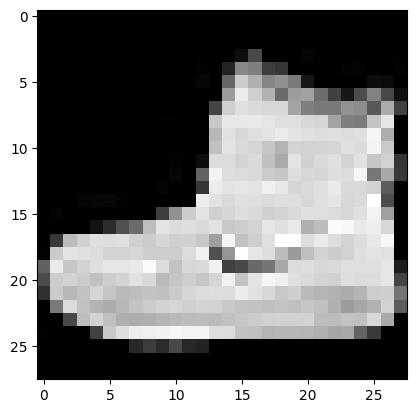

In [62]:
#Primeira imagem para análise
imagem = X_desenvolvimento[0]
#Imagem é uma mtriz de 28 linhas e 28 colunas
print("Formato da imagem", imagem.shape)
#Pixel vai ter um valor de 0 à 255
#0 Representa preto, 255 representa branco
print("Pixel do canto superior esquerdo: ", imagem[0,0])
print("Maior valor de pixel da imagem: ", imagem.max())

#Visualizar uma imagem em tons de cinza
plt.imshow(imagem, cmap='gray')

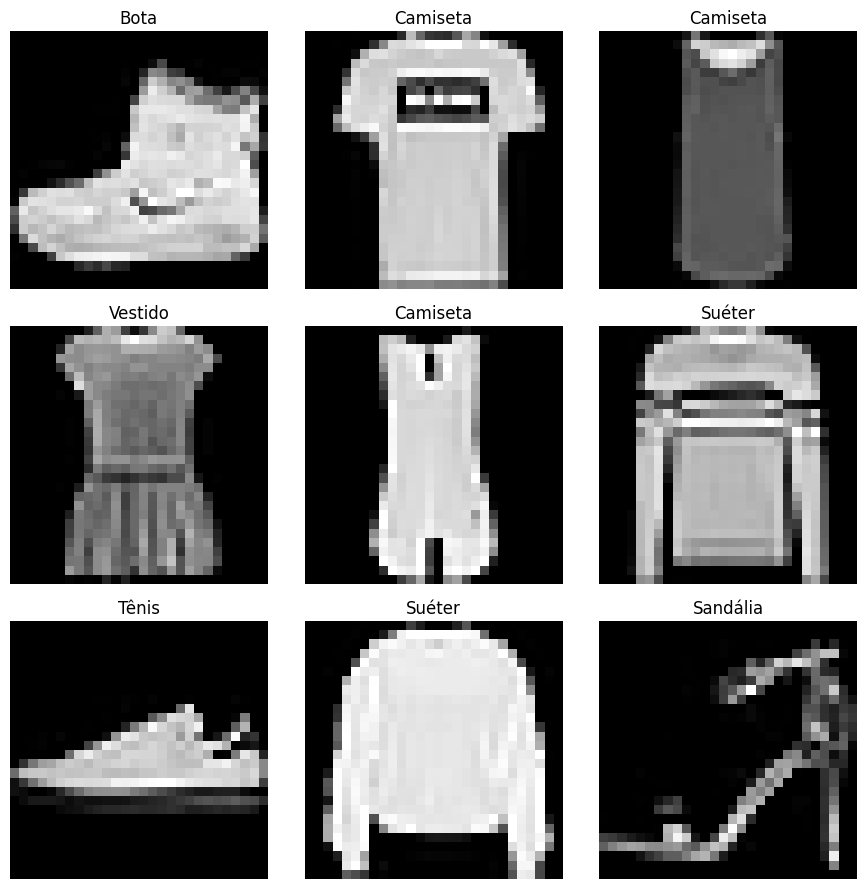

In [63]:
#Exemplo de várias categorias
#criar um quadro com 3 linhas e 3 colunas de imagem
plt.figure(figsize=(9,9))
#Repetir para mostrar as 9 primeiras imagens do dataset
for i in range(9):
  #Indico qual a posição do quadro
  plt.subplot(3,3, i+1)
  #Mostrar a imagem
  plt.imshow(X_desenvolvimento[i], cmap="gray")
  #Nome da peça de roupa
  plt.title(classes[y_desenvolvimento[i]])
  #Remover os eixos
  plt.axis('off')
#ajusta para que os titulos e a imagens não se sobreponham
plt.tight_layout()
plt.show()

In [64]:
#Tirar 10% dos dados para fazer validação
X_treino, X_validacao, y_treino, y_validacao = train_test_split(
    X_desenvolvimento,
    y_desenvolvimento,
    test_size=0.10,
    random_state=42,
    stratify=y_desenvolvimento #Proporção entre classes
    )

print("Treino: ", len(X_treino))
print("Validação: ", len(X_validacao))
print("Teste: ", len(X_teste))

Treino:  54000
Validação:  6000
Teste:  10000


In [65]:
#Normalização
#Pixels são de 0 à 255
#Divido os números por 255, e tenho escala 0 à 1
#Converter em float32 para otimizar os calculos no tensorflow
X_treino = X_treino.astype("float32") / 255.0
X_validacao = X_validacao.astype("float32") / 255.0
X_teste = X_teste.astype("float32") / 255.0

print("Menor valor: ", X_treino.min())
print("Maior valor: ", X_treino.max())

Menor valor:  0.0
Maior valor:  1.0


In [66]:
#28 x 28 x 1 canal
#-1 - calcula automaticamente quantas imagens tem
X_treino = X_treino.reshape(-1, 28, 28, 1)
X_validacao = X_validacao.reshape(-1, 28, 28, 1)
X_teste = X_teste.reshape(-1, 28, 28, 1)

In [67]:
#construção da rde neural
modelo = keras.Sequential()
#Camada de entrada
modelo.add(layers.Input(shape=(28,28,1)))

In [68]:
#Camada convolucional
#Conv2D - Procurar padrões nas regiões das imagens[
#16 filtros diferentes
#Tamanho do filtro 3x3
modelo.add(layers.Conv2D(16, (3,3), activation='relu'))

In [69]:
#MaxPooling2D - Trabalhar com os tamanhos dos padrões
#das caracteriristas
#2,2 - blocos de 2x2 e vai manter o maior valor
modelo.add(layers.MaxPooling2D((2,2)))

In [70]:
#Repito o processo em novas camadas
#32 filtros para aumentar a capacidade do padrão
modelo.add(layers.Conv2D(32, (3,3), activation="relu"))
#reduz novamente o tamanho
modelo.add(layers.MaxPooling2D((2,2)))

In [71]:
#Flatten - Transforma o resultado em 1 único vetor
#Para passar para os neuronios
modelo.add(layers.Flatten())

In [72]:
#64 neurônios
modelo.add(layers.Dense(64, activation="relu"))

In [73]:
#Desativa aleatóriamente 30% das saidas durante o treinamento
modelo.add(layers.Dropout(0.30))

In [74]:
#Camada de saída com 10 neurônios - 1 para cada classe
modelo.add(layers.Dense(10, activation="softmax"))
modelo.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

In [75]:
#Compilador
modelo.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy", #Erro entre diversas classes (0,9)
    metrics=["accuracy"]
)

In [76]:
parada_antecipada = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    min_delta = 0.001, #Melhorias menores que 0.001 não contsm
    restore_best_weights=True
)

In [77]:
historico = modelo.fit(
    X_treino,
    y_treino,
    validation_data=(X_validacao, y_validacao),
    batch_size=128, #Processa 128 imagens por lote
    epochs=12,
    callbacks=[parada_antecipada]
)

Epoch 1/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 24s 52ms/step - accuracy: 0.7330 - loss: 0.7498 - val_accuracy: 0.8368 - val_loss: 0.4469
Epoch 2/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 51ms/step - accuracy: 0.8310 - loss: 0.4716 - val_accuracy: 0.8632 - val_loss: 0.3764
Epoch 3/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 56ms/step - accuracy: 0.8486 - loss: 0.4165 - val_accuracy: 0.8712 - val_loss: 0.3549
Epoch 4/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 22s 53ms/step - accuracy: 0.8604 - loss: 0.3847 - val_accuracy: 0.8803 - val_loss: 0.3319
Epoch 5/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 55ms/step - accuracy: 0.8702 - loss: 0.3573 - val_accuracy: 0.8893 - val_loss: 0.3024
Epoch 6/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 23s 53ms/step - accuracy: 0.8757 - loss: 0.3404 - val_accuracy: 0.8863 - val_loss: 0.2954
Epoch 7/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 26s 62ms/step - accuracy: 0.8812 - loss: 0.3265 - val_accuracy: 0.8953 - val_loss: 0.2870
Epoch 8/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 51s 86ms/step - accuracy: 0.8855 - loss: 0.3108 - 

In [78]:
#Calcular as probabilidades de cada classe
probabilidades = modelo.predict(X_teste, verbose = 0)
#Resultado seja um número de 0 à 9
previsoes = np.argmax(probabilidades, axis=1)
print("Previstos: ", previsoes[:10])

Previstos:  [9 2 1 1 6 1 4 6 5 7]


In [79]:
print("Acuracia", accuracy_score(y_teste, previsoes))

Acuracia 0.8939


In [81]:
matriz = confusion_matrix(y_teste, previsoes)
print(matriz)

[[900   0  13  14   3   2  62   0   6   0]
 [  3 972   0  16   4   0   3   0   2   0]
 [ 17   0 792   6  92   0  91   0   2   0]
 [ 24   5  11 875  42   0  41   0   2   0]
 [  0   1  29  26 866   0  77   0   1   0]
 [  0   0   0   0   0 975   0  16   0   9]
 [157   0  59  20  80   0 673   0  11   0]
 [  0   0   0   0   0  17   0 958   0  25]
 [  5   1   5   2   4   4   5   4 970   0]
 [  0   0   0   0   0   5   0  37   0 958]]
